# Optimización y sensibilidad

Cristhian Pazmino Parra · Universidad Espíritu Santo

Analiza los doce ensayos TPE de diez épocas y los diagnósticos del modelo sustituto.

Referente: anotaciones publicadas sin adjudicación local. Los datos permanecen fuera del repositorio.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "Ejecutar desde la raíz del repositorio"
sys.path.insert(0, str(ROOT))
LOCAL = Path.home() / "AppData/Local/DentalAI"
DATA = LOCAL / "data/research_v2"
REPORTS = ROOT / "reports/completion"
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
from IPython.display import display, Markdown, Image


In [2]:
trials = read(REPORTS / "search_trials.json")
assert len(trials) == 12
selected = read(REPORTS / "selected_configuration.json")
assert max(t["value"] for t in trials) == selected["value"]
display(selected)
display(trials)

{'trial': 9,
 'params': {'lr0': 0.0022391866944421793,
  'weight_decay': 0.0019219976360163777,
  'scale': 0.2279497416264258,
  'imgsz': 960},
 'value': 0.17925537443297865,
 'map50': 0.5880124218385016,
 'map50_95': 0.2523789266030205,
 'run': 'C:\\Users\\crisc\\AppData\\Local\\DentalAI\\runs\\research_v2\\search_09',
 'selection_partition': 'val',
 'budget_epochs': 10}

[{'trial': 0,
  'params': {'lr0': 0.0005514718587869892,
   'weight_decay': 0.0015403596595019247,
   'scale': 0.3061978796339918,
   'imgsz': 640},
  'value': 0.021875871079365745,
  'map50': 0.4669391526975199,
  'map50_95': 0.20103615890514495,
  'run': 'C:\\Users\\crisc\\AppData\\Local\\DentalAI\\runs\\research_v2\\search_00'},
 {'trial': 1,
  'params': {'lr0': 0.0003051362379613694,
   'weight_decay': 1.3603546136118076e-05,
   'scale': 0.3531616510212273,
   'imgsz': 960},
  'value': 0.04759619965053917,
  'map50': 0.5026724120257026,
  'map50_95': 0.22477042181110743,
  'run': 'C:\\Users\\crisc\\AppData\\Local\\DentalAI\\runs\\research_v2\\search_01'},
 {'trial': 2,
  'params': {'lr0': 0.0002114653616703159,
   'weight_decay': 0.0017052641538983103,
   'scale': 0.34135492428014763,
   'imgsz': 640},
  'value': 0.00593112414473422,
  'map50': 0.4377573786037193,
  'map50_95': 0.192773467223728,
  'run': 'C:\\Users\\crisc\\AppData\\Local\\DentalAI\\runs\\research_v2\\search_02'},


In [3]:
sensitivity = read(REPORTS / "search_sensitivity.json")
display(sensitivity["fanova_importance"])
display(sensitivity["leave_one_out"])

{'lr0': 0.5187259383268067,
 'imgsz': 0.25762897528646933,
 'scale': 0.17609512760921783,
 'weight_decay': 0.047549958777506236}

{'r2': 0.6322072484437042,
 'rmse': 0.03708924526868723,
 'observed': [0.021875871079365745,
  0.04759619965053917,
  0.00593112414473422,
  0.01812822330124023,
  0.14332256193895115,
  0.07049717304180393,
  0.15034412383129034,
  0.1593546167789343,
  0.11689547449799574,
  0.17925537443297865,
  0.06032074099923414,
  0.16227476888535225],
 'predicted': [0.057537285358802065,
  0.06630011235773345,
  0.04575647557171937,
  0.049512796851776765,
  0.13503174979681268,
  0.1425397420766996,
  0.13813768330217127,
  0.13882820006263374,
  0.11580691745451208,
  0.12678407389718338,
  0.07476270698709728,
  0.10292386769307983]}

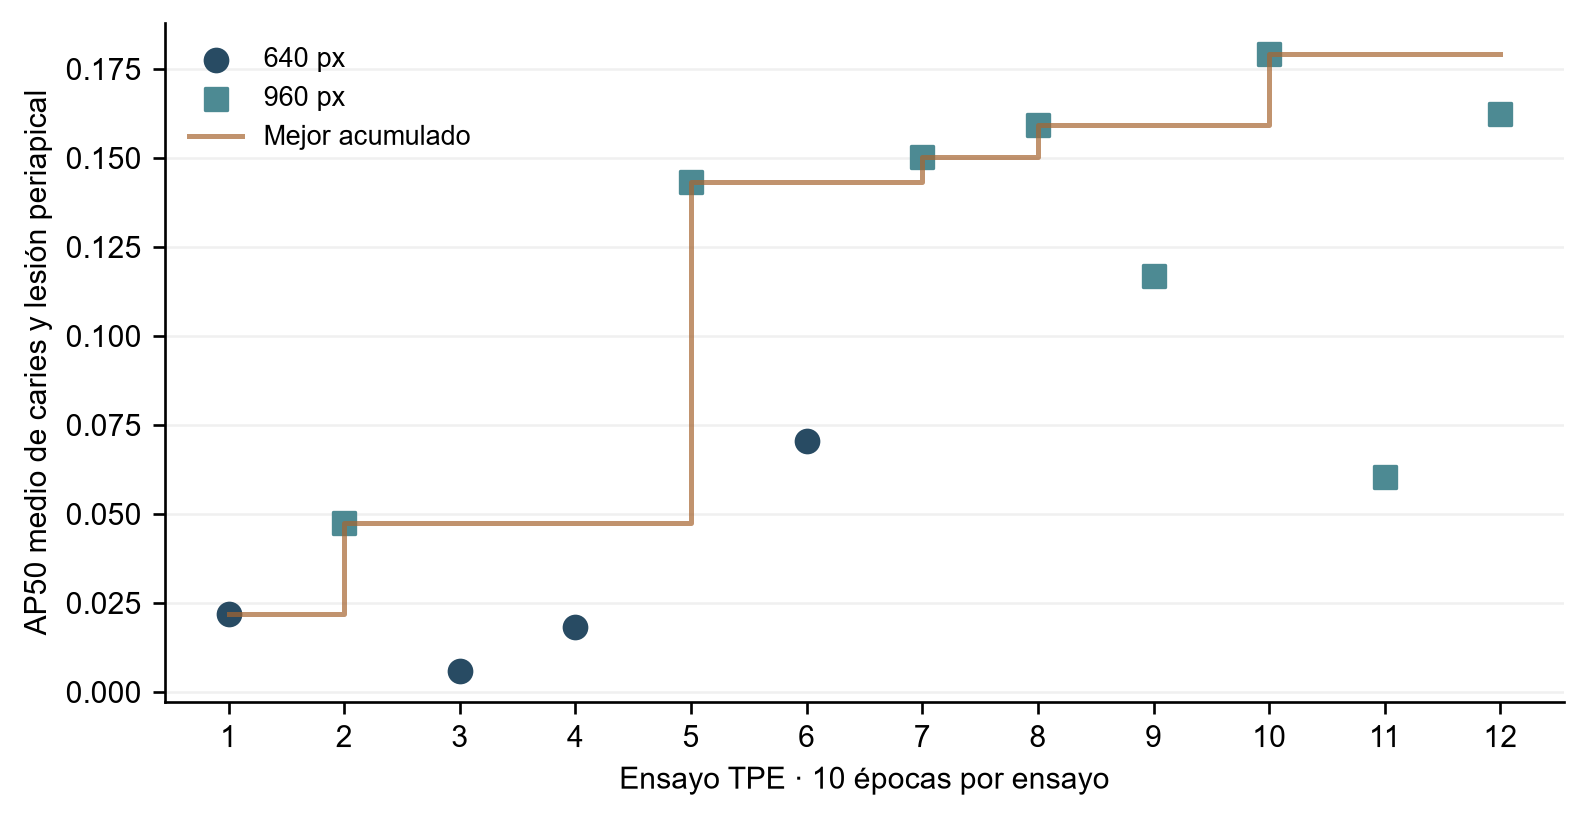

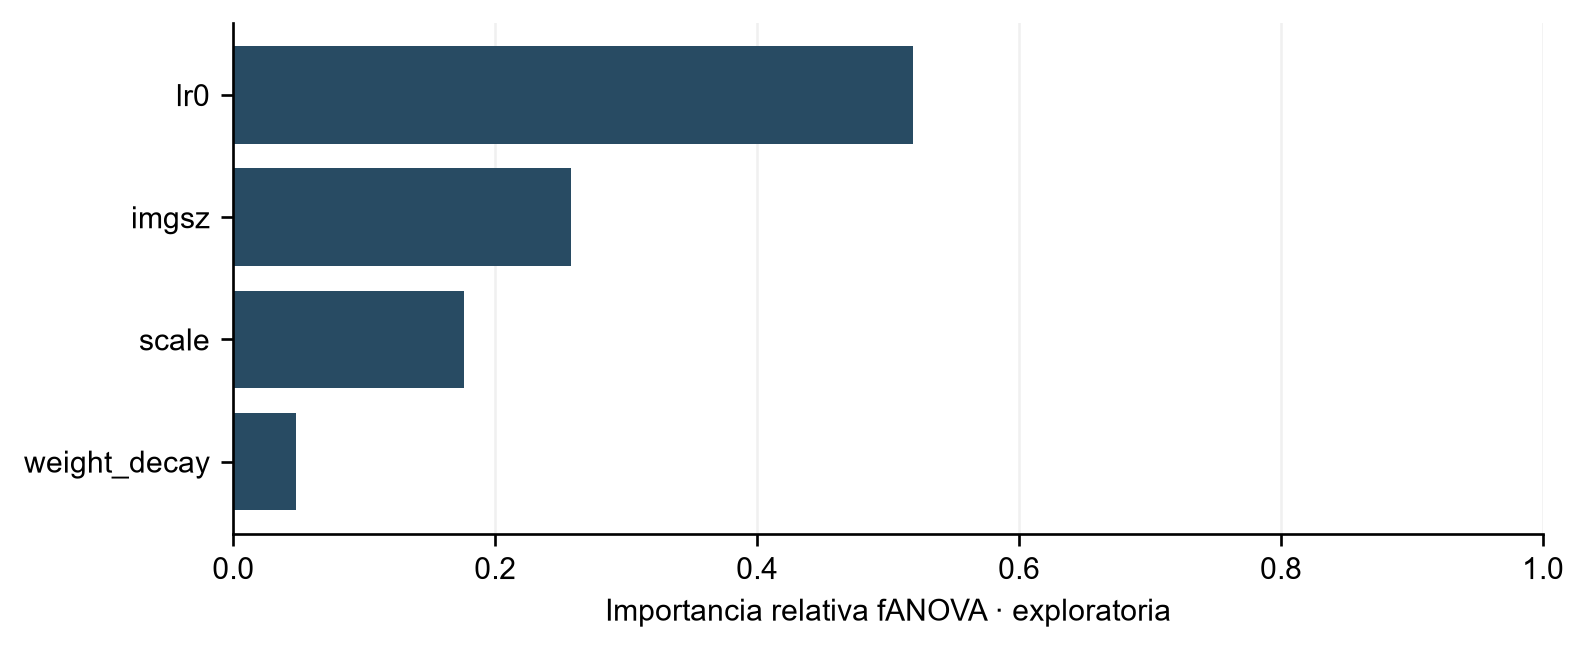

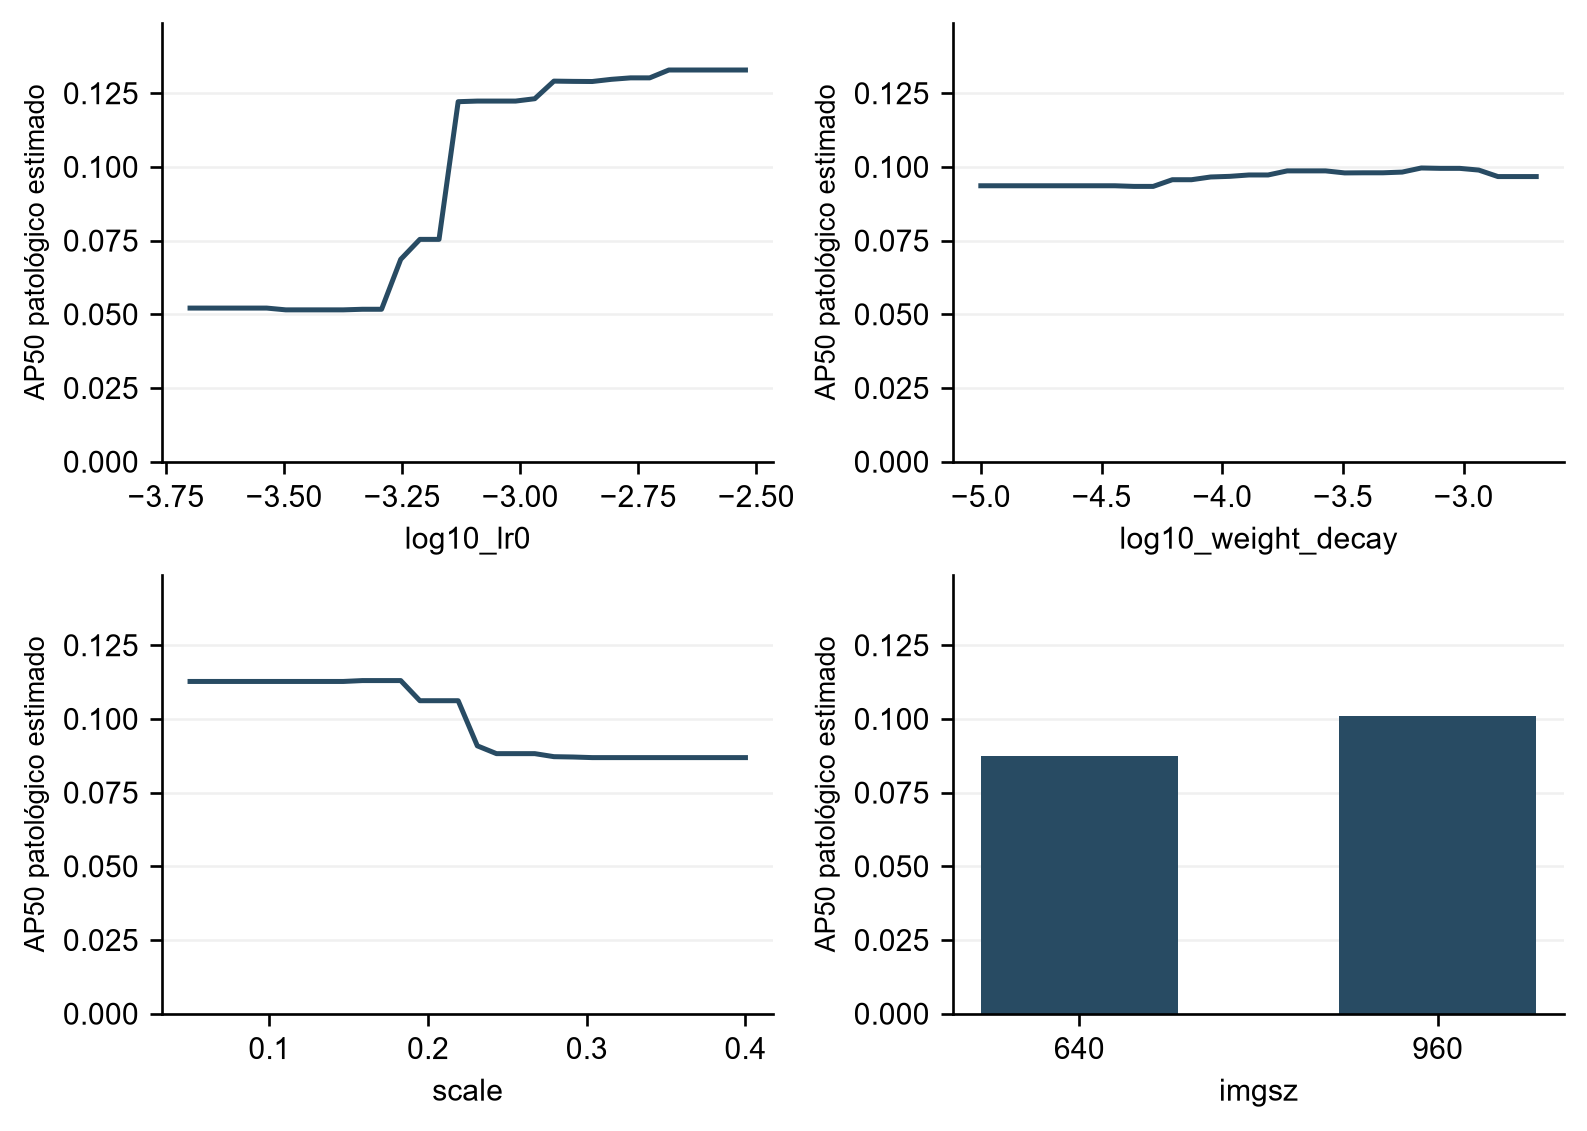

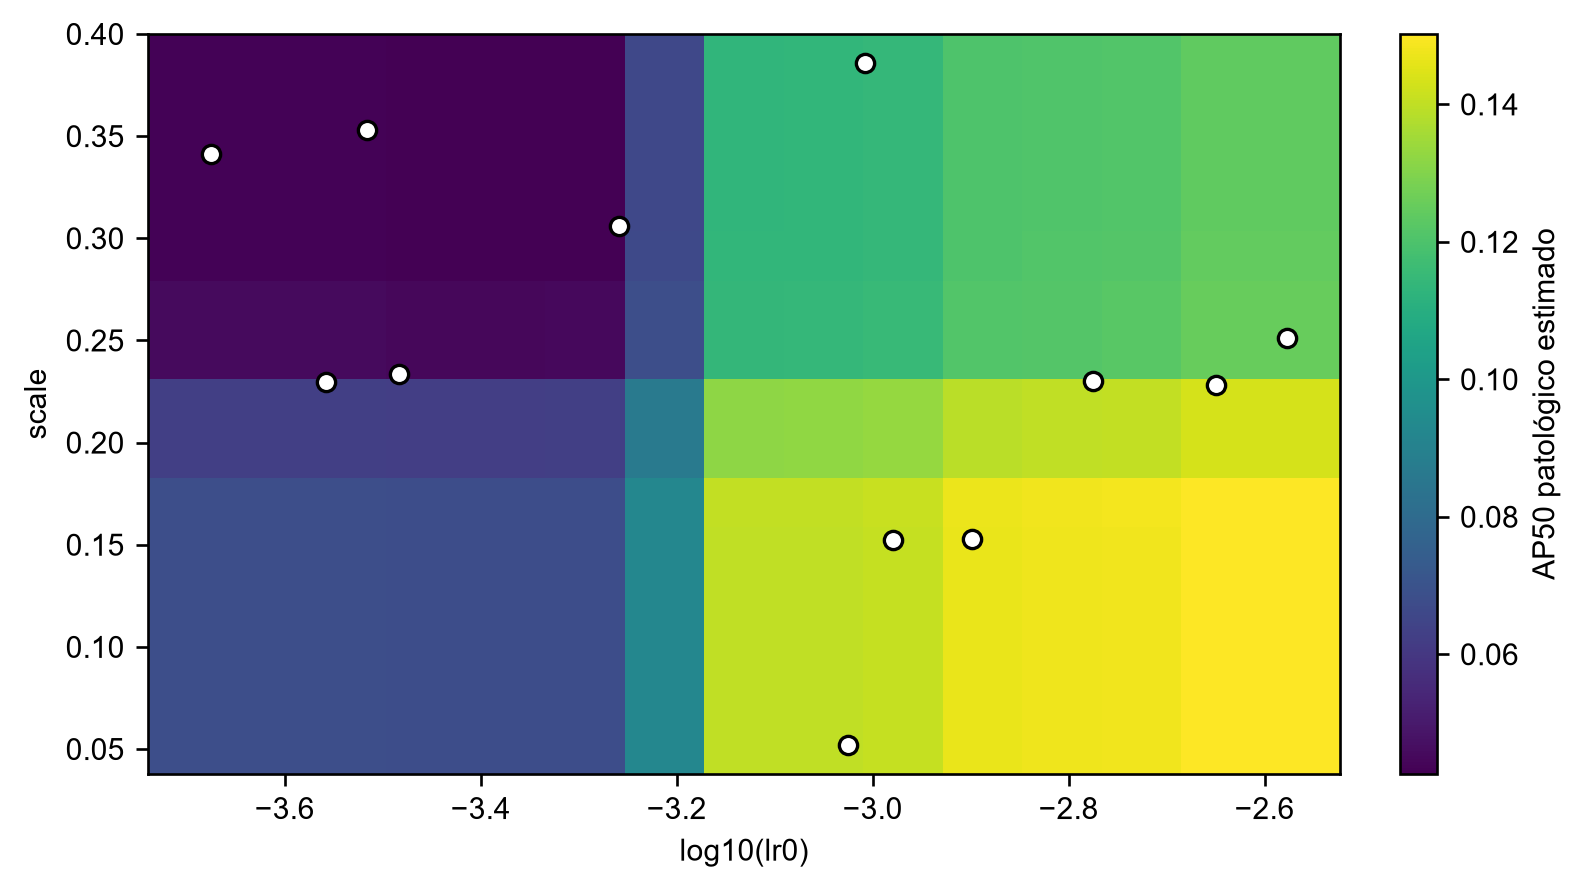

In [4]:
for name in ["v2_08_busqueda.png", "v2_09_importancia.png", "v2_10_pdp.png", "v2_11_interaccion.png"]:
    display(Image(filename=str(ROOT / "output/tesis/figures" / name)))

Los PDP e interacciones describen un sustituto aprendido con doce ensayos de presupuesto reducido. Un R² bajo o negativo fuera de muestra limita su interpretación. No prueban efectos causales ni un óptimo global. Optuna: Akiba et al. (2019), https://doi.org/10.48550/arXiv.1907.10902 .